In [46]:
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/colabsss/precision-agriculture-monitoring-dataset/precision_agriculture_dataset.csv")

df.head()

,timestamp,sensor_node_id,field_zone,latitude,longitude,crop_type,growth_stage,air_temperature_c,relative_humidity_pct,soil_temperature_c,...,leaf_wetness_pct,co2_ppm,evapotranspiration_mm,irrigation_status,irrigation_amount_l,water_flow_rate_l_min,battery_level_pct,signal_strength_dbm,sensor_status,environmental_condition
0,2024-01-01 00:00:00,SN_007,Zone_C,11.696902,78.726563,Tomato,Seedling,22.68,87.98,21.20,...,62.35,418.77,0.62,Off,0.00,0.00,69.23,-86.89,Active,High_Humidity
1,2024-01-01 00:30:00,SN_020,Zone_C,11.025794,79.390131,Cotton,Flowering,21.59,69.39,17.32,...,45.51,425.17,0.89,Off,0.00,0.00,88.45,-77.59,Active,Optimal
2,2024-01-01 01:00:00,SN_029,Zone_C,12.092548,78.785863,Maize,Seedling,19.60,79.59,19.86,...,42.12,493.87,0.50,Off,0.00,0.00,77.51,-48.27,Active,Adverse
3,2024-01-01 01:30:00,SN_015,Zone_D,12.923650,78.570311,Maize,Fruiting,20.51,77.78,18.18,...,49.81,457.19,0.74,On,40.54,4.63,83.10,-60.33,Active,Dry_Stress
4,2024-01-01 02:00:00,SN_011,Zone_B,12.202847,78.882257,Wheat,Fruiting,22.69,60.38,21.31,...,22.05,397.79,1.06,Off,0.00,0.00,81.62,-63.55,Active,Optimal


In [47]:
# 1. Type actuel de la colonne
print(df["timestamp"].dtype)

# 2. Conversion en vrai format date
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

# 3. Période couverte par les données
print(df["timestamp"].min(), df["timestamp"].max())

# 4. Les lignes sont-elles déjà triées dans l'ordre chronologique ?
print(df["timestamp"].is_monotonic_increasing)

# 5. Combien de dates invalides après conversion ?
print(df["timestamp"].isna().sum())

object
2024-01-01 00:00:00 2024-11-08 11:30:00
True
0


In [48]:
# 1. Écart entre chaque timestamp et le précédent
ecarts = df["timestamp"].diff()

# 2. Fréquence de chaque écart (en proportion)
print(ecarts.value_counts(normalize=True).head())

# 3. Écart minimum et maximum
print(ecarts.min(), ecarts.max())

# 4. Doublons : combien de timestamps apparaissent plusieurs fois ?
print(df["timestamp"].duplicated().sum())

timestamp
0 days 00:30:00    1.0
Name: proportion, dtype: float64
0 days 00:30:00 0 days 00:30:00
0


In [49]:
# 1. Nombre de capteurs et de zones distincts
print('Nombre de capteurs et de zones distincts : ')
print(df["sensor_node_id"].nunique(), df["field_zone"].nunique())

# 2. Les 10 premières lignes : quel capteur / quelle zone à chaque instant ?
print(df[["timestamp", "sensor_node_id", "field_zone"]].head(10))

# 3. Un même capteur apparaît-il dans plusieurs zones ?
print(df.groupby("sensor_node_id")["field_zone"].nunique().describe())

Nombre de capteurs et de zones distincts : 
30 5
            timestamp sensor_node_id field_zone
0 2024-01-01 00:00:00         SN_007     Zone_C
1 2024-01-01 00:30:00         SN_020     Zone_C
2 2024-01-01 01:00:00         SN_029     Zone_C
3 2024-01-01 01:30:00         SN_015     Zone_D
4 2024-01-01 02:00:00         SN_011     Zone_B
5 2024-01-01 02:30:00         SN_008     Zone_E
6 2024-01-01 03:00:00         SN_029     Zone_E
7 2024-01-01 03:30:00         SN_021     Zone_C
8 2024-01-01 04:00:00         SN_007     Zone_E
9 2024-01-01 04:30:00         SN_026     Zone_E
count    30.0
mean      5.0
std       0.0
min       5.0
25%       5.0
50%       5.0
75%       5.0
max       5.0
Name: field_zone, dtype: float64


In [50]:
# 1. Combien de positions (latitude, longitude) distinctes par capteur ?
print(df.groupby("sensor_node_id")[["latitude", "longitude"]].nunique().head())

# 2. Tableau croisé capteur x zone (extrait)
print(pd.crosstab(df["sensor_node_id"], df["field_zone"]).head())

                latitude  longitude
sensor_node_id                     
SN_001               500        500
SN_002               492        492
SN_003               506        506
SN_004               492        492
SN_005               491        491
field_zone      Zone_A  Zone_B  Zone_C  Zone_D  Zone_E
sensor_node_id                                        
SN_001              92      97      96     100     116
SN_002              84      99     104      95     110
SN_003             101     103      97     104     101
SN_004             110     105      88      97      92
SN_005              98     109      79      93     112


In [51]:
# Autocorrélation à lag 1 (30 min) pour la température de l'air
print(df["air_temperature_c"].autocorr(lag=1))

# Autocorrélation à lag 48 (48 pas de 30 min = 24 h)
print(df["air_temperature_c"].autocorr(lag=48))

# Même chose pour l'humidité du sol
print(df["soil_moisture_pct"].autocorr(lag=1))

0.8371716358992075
0.8478370878512478
-0.005378156046763767


In [52]:
# Extraire l'heure de la journée (0 à 23)
df["heure"] = df["timestamp"].dt.hour

# Température moyenne par heure
print(df.groupby("heure")["air_temperature_c"].mean().round(1))

# Même chose pour l'humidité du sol
print(df.groupby("heure")["soil_moisture_pct"].mean().round(1))

heure
0     20.8
1     21.1
2     21.9
3     22.7
4     24.0
5     25.4
6     27.1
7     28.5
8     30.0
9     31.4
10    32.1
11    32.8
12    33.1
13    32.8
14    32.2
15    31.3
16    30.0
17    28.6
18    26.9
19    25.5
20    23.9
21    22.7
22    21.8
23    21.1
Name: air_temperature_c, dtype: float64
heure
0     46.0
1     45.8
2     45.8
3     45.6
4     46.2
5     46.7
6     46.6
7     45.7
8     45.9
9     46.3
10    46.3
11    45.4
12    45.4
13    44.9
14    47.0
15    46.2
16    44.4
17    46.4
18    45.8
19    46.0
20    45.6
21    45.7
22    46.0
23    45.4
Name: soil_moisture_pct, dtype: float64


In [53]:
# Extraire le mois (1 à 12)
df["mois"] = df["timestamp"].dt.month

# Proportion de chaque classe dans chaque mois (chaque ligne somme à 1)
tableau = pd.crosstab(df["mois"], df["environmental_condition"], normalize="index")
print(tableau.round(2))

environmental_condition  Adverse  Dry_Stress  Heat_Stress  High_Humidity  \
mois                                                                       
1                           0.21        0.24         0.04           0.07   
2                           0.23        0.24         0.04           0.07   
3                           0.24        0.24         0.03           0.08   
4                           0.20        0.24         0.04           0.08   
5                           0.24        0.22         0.04           0.07   
6                           0.23        0.21         0.05           0.07   
7                           0.23        0.22         0.05           0.08   
8                           0.22        0.26         0.04           0.07   
9                           0.22        0.22         0.05           0.08   
10                          0.24        0.26         0.04           0.07   
11                          0.20        0.25         0.05           0.08   

environment

In [54]:
# Classe de la ligne précédente
df["cible_precedente"] = df["environmental_condition"].shift(1)

# Part des lignes dont la classe est identique à la précédente
observee = (df["environmental_condition"] == df["cible_precedente"]).iloc[1:].mean()

# Part attendue si les classes étaient indépendantes dans le temps (somme des p²)
p = df["environmental_condition"].value_counts(normalize=True)
attendue = (p ** 2).sum()

print(observee, attendue)

0.35755717047803187 0.29446275555555557


In [55]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox

for var in ["air_temperature_c", "soil_moisture_pct"]:
    serie = df[var].dropna()

    # Test ADF (stationnarité) : on garde la p-value (indice 1)
    p_adf = adfuller(serie, autolag="AIC", result_object=False)[1]

    # Test de Ljung-Box (dépendance) jusqu'au lag 48
    p_lb = acorr_ljungbox(serie, lags=[48], return_df=True)["lb_pvalue"].iloc[0]

    print(var, "| ADF p =", round(p_adf, 4), "| Ljung-Box p =", round(p_lb, 4))

air_temperature_c | ADF p = 0.0 | Ljung-Box p = 0.0
soil_moisture_pct | ADF p = 0.0 | Ljung-Box p = 0.3969


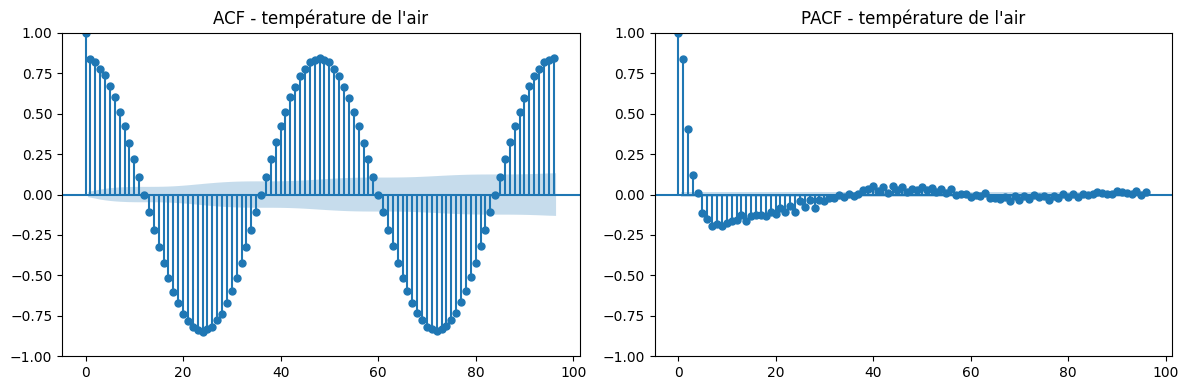

In [56]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

serie = df["air_temperature_c"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# ACF : corrélation avec chaque décalage
plot_acf(serie, lags=96, ax=axes[0],
         title="ACF - température de l'air")

# PACF : corrélation directe
plot_pacf(serie, lags=96, ax=axes[1],
          title="PACF - température de l'air", method="ywm")

plt.tight_layout()
plt.savefig("acf_pacf_temperature.png", dpi=120)  # pour le rapport

plt.show()


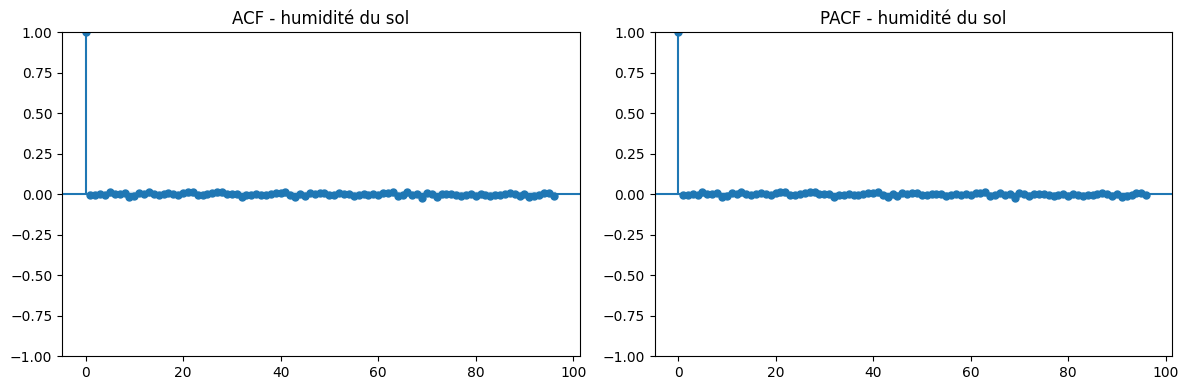

In [57]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Série à analyser : humidité du sol (au lieu de la température de l'air)
serie = df["soil_moisture_pct"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# ACF : corrélation avec chaque décalage, jusqu'à 2 jours (96 pas de 30 min)
plot_acf(serie, lags=96, ax=axes[0], title="ACF - humidité du sol")

# PACF : corrélation « directe » (sans l'effet des décalages intermédiaires)
plot_pacf(serie, lags=96, ax=axes[1], title="PACF - humidité du sol", method="ywm")

plt.tight_layout()
plt.savefig("acf_pacf_humidite_sol.png", dpi=120)  # pour le rapport
plt.show()

In [58]:
x = df["solar_radiation_w_m2"]   # rayonnement solaire
y = df["air_temperature_c"]      # température de l'air

for k in [0, 1, 2, 6, 12, 24, 48]:
    # x décalé de k pas : valeur de x observée k pas AVANT chaque valeur de y
    corr = y.corr(x.shift(k))
    print("lag", k, "->", round(corr, 3))

lag 0 -> 0.819
lag 1 -> 0.806
lag 2 -> 0.791
lag 6 -> 0.579
lag 12 -> 0.0
lag 24 -> -0.823
lag 48 -> 0.819


In [59]:
x = df["solar_radiation_w_m2"]
y = df["air_temperature_c"]

# k négatif : on décale x vers le futur, donc on teste si y précède x
for k in [-12, -6, -2, -1, 0, 1, 2, 6, 12]:
    corr = y.corr(x.shift(k))
    print("lag", k, "->", round(corr, 3))

lag -12 -> 0.004
lag -6 -> 0.58
lag -2 -> 0.79
lag -1 -> 0.805
lag 0 -> 0.819
lag 1 -> 0.806
lag 2 -> 0.791
lag 6 -> 0.579
lag 12 -> 0.0


In [60]:
SEED = 42  # graine globale du projet

n = len(df)
n_test = int(n * 0.2)  # 20 % des lignes pour le test

# df est déjà trié chronologiquement : le test = les dernières lignes
dev = df.iloc[: n - n_test]    # développement (train + validation)
test = df.iloc[n - n_test :]   # test verrouillé

print("Dev :", dev["timestamp"].min(), "->", dev["timestamp"].max())
print("Test:", test["timestamp"].min(), "->", test["timestamp"].max())

# Les proportions des classes sont-elles proches entre dev et test ?
print(dev["environmental_condition"].value_counts(normalize=True).round(3))
print(test["environmental_condition"].value_counts(normalize=True).round(3))


Dev : 2024-01-01 00:00:00 -> 2024-09-06 23:30:00
Test: 2024-09-07 00:00:00 -> 2024-11-08 11:30:00
environmental_condition
Optimal          0.428
Dry_Stress       0.235
Adverse          0.223
High_Humidity    0.073
Heat_Stress      0.040
Name: proportion, dtype: float64
environmental_condition
Optimal          0.415
Dry_Stress       0.244
Adverse          0.227
High_Humidity    0.073
Heat_Stress      0.041
Name: proportion, dtype: float64


In [61]:
import os
import pandas as pd

resultats = []  # liste de lignes : section, metrique, valeur

def add(section, metrique, valeur):
    resultats.append({
        "section": section,
        "metrique": metrique,
        "valeur": valeur
    })

# Exemples déjà remplis
add("general", "n_lignes", df.shape[0])
add("timestamp", "date_min", df["timestamp"].min())
add("timestamp", "pas_dominant", ecarts.value_counts().index[0])

# À compléter
add("timestamp", "n_doublons", df["timestamp"].duplicated().sum())
add("capteur_zone", "n_capteurs", df["sensor_node_id"].nunique())
add("autocorrelation", "air_temperature_c_lag1",
    df["air_temperature_c"].autocorr(lag=1))

# Sauvegarde dans le dossier de sortie de Kaggle
os.makedirs("/kaggle/working/results", exist_ok=True)

pd.DataFrame(resultats).to_csv(
    "/kaggle/working/results/Exploratory_temporal.csv",
    index=False,
    encoding="utf-8"
)

print("Fichier enregistré avec succès !")


Fichier enregistré avec succès !


In [62]:
# Horodatage
add("timestamp", "date_max", df["timestamp"].max())
add("timestamp", "ordre_chronologique", df["timestamp"].is_monotonic_increasing)

# Capteurs / zones
add("capteur_zone", "n_zones", df["field_zone"].nunique())
add("capteur_zone", "zones_par_capteur_max",
    df.groupby("sensor_node_id")["field_zone"].nunique().max())

# Autocorrélation
add("autocorrelation", "air_temperature_c_lag48", df["air_temperature_c"].autocorr(lag=48))
add("autocorrelation", "soil_moisture_pct_lag1", df["soil_moisture_pct"].autocorr(lag=1))

# Persistance de la cible (variables calculées plus haut)
add("cible", "persistance_observee", observee)
add("cible", "persistance_attendue", attendue)

# Découpage développement / test
add("split", "dev_date_fin", dev["timestamp"].max())
add("split", "test_date_debut", test["timestamp"].min())

# Sauvegarde
pd.DataFrame(resultats).to_csv(
    "/kaggle/working/results/Exploratory_temporal.csv",
    index=False,
    encoding="utf-8"
)


In [63]:
# Nombre de lignes dans la liste en mémoire
print(len(resultats))

# Contenu réel du fichier sauvegardé
print(pd.read_csv("/kaggle/working/results/Exploratory_temporal.csv"))

16
            section                 metrique                 valeur
0           general                 n_lignes                  15000
1         timestamp                 date_min    2024-01-01 00:00:00
2         timestamp             pas_dominant        0 days 00:30:00
3         timestamp               n_doublons                      0
4      capteur_zone               n_capteurs                     30
5   autocorrelation   air_temperature_c_lag1     0.8371716358992075
6         timestamp                 date_max    2024-11-08 11:30:00
7         timestamp      ordre_chronologique                   True
8      capteur_zone                  n_zones                      5
9      capteur_zone    zones_par_capteur_max                      5
10  autocorrelation  air_temperature_c_lag48     0.8478370878512478
11  autocorrelation   soil_moisture_pct_lag1  -0.005378156046763767
12            cible     persistance_observee    0.35755717047803187
13            cible     persistance_attendue 

In [64]:
# Supprimer les lignes en double (même section, même métrique, même valeur)
df_res = pd.DataFrame(resultats).drop_duplicates()

# Vérification : on attend 16 lignes
print(len(df_res))

# Sauvegarde : le fichier précédent est remplacé
df_res.to_csv(
    "/kaggle/working/results/Exploratory_temporal.csv", index=False, encoding="utf-8"
)

16


In [65]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox

for var in ["air_temperature_c", "soil_moisture_pct"]:
    serie = df[var].dropna()

    # p-values des deux tests
    p_adf = adfuller(serie, autolag="AIC", result_object=False)[1]
    p_lb = acorr_ljungbox(
        serie, lags=[48], return_df=True
    )["lb_pvalue"].iloc[0]

    add("tests", f"{var}_adf_pvalue", p_adf)
    add("tests", f"{var}_ljungbox_lag48_pvalue", p_lb)

# Supprimer les doublons éventuels puis sauvegarder
df_res = pd.DataFrame(resultats).drop_duplicates()
print(len(df_res))  # on attend 20 lignes

df_res.to_csv(
    "/kaggle/working/results/Exploratory_temporal.csv",
    index=False,
    encoding="utf-8"
)


20


In [66]:
# 1. Positions : combien de positions (latitude) distinctes par capteur, en moyenne ?
n_pos = df.groupby("sensor_node_id")["latitude"].nunique()
add("capteur_zone", "positions_distinctes_moyenne_par_capteur", n_pos.mean())

# Combien de lignes (observations) par capteur, en moyenne ?
n_obs = df.groupby("sensor_node_id").size()
add("capteur_zone", "observations_moyenne_par_capteur", n_obs.mean())

# 2. Cycle journalier de la température de l'air (colonne "heure" créée plus haut)
moy_heure = df.groupby("heure")["air_temperature_c"].mean()
add("cycle_journalier", "temp_moyenne_min", moy_heure.min())
add("cycle_journalier", "temp_moyenne_max", moy_heure.max())
add("cycle_journalier", "heure_du_max", moy_heure.idxmax())

# Suppression des doublons puis sauvegarde
df_res = pd.DataFrame(resultats).drop_duplicates()
print(len(df_res))  # on attend 25 lignes

df_res.to_csv(
    "/kaggle/working/results/Exploratory_temporal.csv",
    index=False,
    encoding="utf-8"
)


25


In [67]:
from sklearn.model_selection import RepeatedStratifiedKFold

SEED = 42  # graine globale du projet
y_dev = dev["environmental_condition"]

# 10 plis, répétés 3 fois
rskf = RepeatedStratifiedKFold(
    n_splits=10,
    n_repeats=3,
    random_state=SEED
)

lignes_splits = []

for i, (idx_train, idx_val) in enumerate(rskf.split(dev, y_dev)):
    repetition = i // 10   # 0, 1 ou 2
    pli = i % 10           # 0 à 9

    # On garde les index d'origine du DataFrame
    for idx in dev.index[idx_val]:
        lignes_splits.append({
            "repetition": repetition,
            "fold": pli,
            "index": idx
        })

splits = pd.DataFrame(lignes_splits)

print(splits.shape)
print(splits.groupby(["repetition", "fold"]).size().head())


(36000, 3)
repetition  fold
0           0       1200
            1       1200
            2       1200
            3       1200
            4       1200
dtype: int64


In [68]:
# 1. Chaque ligne du dev doit apparaître exactement 1 fois par répétition
verif = splits.groupby(["repetition", "index"]).count()
print(verif.max())  # attendu : 1

# 2. Proportions des classes dans le pli 0 de la répétition 0
pli0 = splits[(splits["repetition"] == 0) & (splits["fold"] == 0)]
print(dev.loc[pli0["index"], "environmental_condition"].value_counts(normalize=True).round(3))

# 3. Le pli 0 de la répétition 1 est-il différent de celui de la répétition 0 ?
pli0_rep1 = splits[(splits["repetition"] == 1) & (splits["fold"] == 0)]
commun = len(set(pli0["index"]) & set(pli0_rep1["index"]))
print(commun)


fold    1
dtype: int64
environmental_condition
Optimal          0.428
Dry_Stress       0.235
Adverse          0.223
High_Humidity    0.073
Heat_Stress      0.040
Name: proportion, dtype: float64
114


In [69]:
import os

dossier = "/kaggle/working/results/splits"
os.makedirs(dossier, exist_ok=True)

# Plis de validation (3 répétitions x 10 plis)
splits.to_csv(f"{dossier}/splits_validation.csv", index=False)

# Indices du développement et du test verrouillé
pd.DataFrame({"index": dev.index}).to_csv(f"{dossier}/dev_index.csv", index=False)
pd.DataFrame({"index": test.index}).to_csv(f"{dossier}/test_index.csv", index=False)

# Vérification : on recharge et on reconstruit l'entraînement du pli 0 / répétition 0
val = pd.read_csv(f"{dossier}/splits_validation.csv")
val_idx = val[(val["repetition"] == 0) & (val["fold"] == 0)]["index"]
dev_idx = pd.read_csv(f"{dossier}/dev_index.csv")["index"]
train_idx = dev_idx[~dev_idx.isin(val_idx)]
print(len(train_idx), len(val_idx))


10800 1200


In [70]:
from sklearn.model_selection import TimeSeriesSplit

# dev est trié chronologiquement : TimeSeriesSplit respecte l'ordre des lignes
# gap=48 : on laisse 24 h (48 pas) entre l'entraînement et la validation
tscv = TimeSeriesSplit(n_splits=5, gap=48)

for pli, (idx_train, idx_val) in enumerate(tscv.split(dev)):
    t_train = dev["timestamp"].iloc[idx_train]
    t_val = dev["timestamp"].iloc[idx_val]
    print(f"pli {pli} | train : {len(idx_train)} lignes, fin {t_train.max()} "
          f"| val : {len(idx_val)} lignes, début {t_val.min()}")


pli 0 | train : 1952 lignes, fin 2024-02-10 15:30:00 | val : 2000 lignes, début 2024-02-11 16:00:00
pli 1 | train : 3952 lignes, fin 2024-03-23 07:30:00 | val : 2000 lignes, début 2024-03-24 08:00:00
pli 2 | train : 5952 lignes, fin 2024-05-03 23:30:00 | val : 2000 lignes, début 2024-05-05 00:00:00
pli 3 | train : 7952 lignes, fin 2024-06-14 15:30:00 | val : 2000 lignes, début 2024-06-15 16:00:00
pli 4 | train : 9952 lignes, fin 2024-07-26 07:30:00 | val : 2000 lignes, début 2024-07-27 08:00:00


In [71]:
lignes_ts = []

for pli, (idx_train, idx_val) in enumerate(tscv.split(dev)):
    for idx in dev.index[idx_train]:
        lignes_ts.append({"fold": pli, "ensemble": "train", "index": idx})

    for idx in dev.index[idx_val]:
        lignes_ts.append({"fold": pli, "ensemble": "val", "index": idx})

splits_ts = pd.DataFrame(lignes_ts)
splits_ts.to_csv(f"{dossier}/splits_temporel.csv", index=False)

print(splits_ts.groupby(["fold", "ensemble"]).size().unstack())

# Proportions des classes dans chaque pli de validation temporel
val_ts = splits_ts[splits_ts["ensemble"] == "val"].copy()
val_ts["classe"] = dev.loc[val_ts["index"], "environmental_condition"].values

print(pd.crosstab(
    val_ts["fold"],
    val_ts["classe"],
    normalize="index"
).round(3))


ensemble  train   val
fold                 
0          1952  2000
1          3952  2000
2          5952  2000
3          7952  2000
4          9952  2000
classe  Adverse  Dry_Stress  Heat_Stress  High_Humidity  Optimal
fold                                                            
0         0.233       0.250        0.033          0.067    0.418
1         0.214       0.234        0.040          0.077    0.436
2         0.242       0.216        0.044          0.074    0.426
3         0.216       0.222        0.047          0.077    0.438
4         0.219       0.252        0.041          0.070    0.418


In [72]:
!mkdir -p src
!ls -la /kaggle/working/src

total 20
drwxr-xr-x 2 root root 4096 Nov  3 08:54 .
drwxr-xr-x 5 root root 4096 Nov  3 08:54 ..
-rw-r--r-- 1 root root 4266 Nov  3 08:54 make_splits.py
-rw-r--r-- 1 root root 3496 Nov  3 08:59 temporal_features.py


In [73]:
%%writefile /kaggle/working/src/make_splits.py
"""make_splits.py : génère le test verrouillé et les plis de validation.

Usage : python src/make_splits.py chemin/vers/dataset.csv
Sorties (dans results/splits/) :
    dev_index.csv, test_index.csv, splits_validation.csv, splits_temporel.csv
Les colonnes "index" contiennent les index de lignes du CSV ORIGINAL
(utiliser df.loc[index] après avoir lu le même fichier, sans le trier ni le filtrer).
"""
import os
import sys

import pandas as pd
from sklearn.model_selection import RepeatedStratifiedKFold, TimeSeriesSplit

SEED = 42             # graine globale du projet
FRACTION_TEST = 0.2   # 20 % des dernières lignes (chronologiques) pour le test
N_PLIS = 10           # validation croisée stratifiée : 10 plis
N_REPETITIONS = 3     # répétée 3 fois (3 x 10 = 30 scores par modèle)
N_PLIS_TEMPORELS = 5  # TimeSeriesSplit : 5 plis
GAP = 48              # 48 pas de 30 min = 24 h entre entraînement et validation
GAP_DEV_TEST = 48     # 24 h écartées entre la fin du développement et le début du test
CIBLE = "environmental_condition"
SORTIE = "results/splits"


def charger(chemin):
    """Lit le CSV, convertit la date et vérifie l'ordre chronologique."""
    df = pd.read_csv(chemin)
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    assert df["timestamp"].is_monotonic_increasing, "Les données ne sont pas triées par date"
    return df


def separer_test(df):
    """Le test = les dernières lignes (le df est trié chronologiquement)."""
    n = len(df)
    n_test = int(n * FRACTION_TEST)
    # On retire les GAP_DEV_TEST dernières lignes du dev : elles ne sont ni dans le dev
    # ni dans le test, pour éviter que les premières lignes du test ressemblent
    # (corrélation temporelle) aux dernières lignes d'entraînement.
    dev = df.iloc[: n - n_test - GAP_DEV_TEST]
    test = df.iloc[n - n_test:]
    return dev, test


def plis_stratifies(dev):
    """3 répétitions x 10 plis stratifiés sur le développement.
    On enregistre uniquement les lignes de validation de chaque pli ;
    l'entraînement = tout le développement privé de ces lignes."""
    y_dev = dev[CIBLE]
    rskf = RepeatedStratifiedKFold(
        n_splits=N_PLIS, n_repeats=N_REPETITIONS, random_state=SEED
    )
    lignes = []
    for i, (_, idx_val) in enumerate(rskf.split(dev, y_dev)):
        repetition = i // N_PLIS
        pli = i % N_PLIS
        for idx in dev.index[idx_val]:
            lignes.append({"repetition": repetition, "fold": pli, "index": idx})
    return pd.DataFrame(lignes)


def plis_temporels(dev):
    """TimeSeriesSplit : on s'entraîne sur le passé, on valide sur la période suivante.
    Ici l'entraînement n'est pas « le reste » (à cause du gap), donc on l'enregistre."""
    tscv = TimeSeriesSplit(n_splits=N_PLIS_TEMPORELS, gap=GAP)
    lignes = []
    for pli, (idx_train, idx_val) in enumerate(tscv.split(dev)):
        for idx in dev.index[idx_train]:
            lignes.append({"fold": pli, "ensemble": "train", "index": idx})
        for idx in dev.index[idx_val]:
            lignes.append({"fold": pli, "ensemble": "val", "index": idx})
    return pd.DataFrame(lignes)


if __name__ == "__main__":
    if len(sys.argv) < 2:
        sys.exit("Usage : python src/make_splits.py chemin/vers/dataset.csv")

    os.makedirs(SORTIE, exist_ok=True)
    df = charger(sys.argv[1])
    dev, test = separer_test(df)

    splits = plis_stratifies(dev)
    splits_ts = plis_temporels(dev)

    # Vérifications de cohérence (le script s'arrête si quelque chose ne va pas)
    assert len(set(dev.index) & set(test.index)) == 0, "Fuite : dev et test se chevauchent"
    assert len(splits) == len(dev) * N_REPETITIONS, "Nombre de lignes de validation inattendu"

    pd.DataFrame({"index": dev.index}).to_csv(f"{SORTIE}/dev_index.csv", index=False)
    pd.DataFrame({"index": test.index}).to_csv(f"{SORTIE}/test_index.csv", index=False)
    splits.to_csv(f"{SORTIE}/splits_validation.csv", index=False)
    splits_ts.to_csv(f"{SORTIE}/splits_temporel.csv", index=False)

    print(f"Dev : {len(dev)} lignes | Test : {len(test)} lignes")
    print(f"Plis stratifiés : {len(splits)} lignes de validation")
    print(f"Plis temporels : {len(splits_ts)} lignes")
    print(f"Fichiers écrits dans {SORTIE}/")

Overwriting /kaggle/working/src/make_splits.py


In [74]:
!ls -l /kaggle/working/src

total 12
-rw-r--r-- 1 root root 4266 Nov  3 09:06 make_splits.py
-rw-r--r-- 1 root root 3496 Nov  3 08:59 temporal_features.py


In [75]:
import os

for racine, dossiers, fichiers in os.walk("/kaggle/input"):
    for fichier in fichiers:
        if fichier.endswith(".csv"):
            print(os.path.join(racine, fichier))

/kaggle/input/datasets/colabsss/precision-agriculture-monitoring-dataset/precision_agriculture_dataset.csv


In [76]:
!python /kaggle/working/src/make_splits.py "/kaggle/input/datasets/colabsss/precision-agriculture-monitoring-dataset/precision_agriculture_dataset.csv"


Dev : 11952 lignes | Test : 3000 lignes
Plis stratifiés : 35856 lignes de validation
Plis temporels : 39600 lignes
Fichiers écrits dans results/splits/


In [77]:
!ls -lh /kaggle/working/results/splits/


total 880K
-rw-r--r-- 1 root root  60K Nov  3 09:06 dev_index.csv
-rw-r--r-- 1 root root 480K Nov  3 09:06 splits_temporel.csv
-rw-r--r-- 1 root root 318K Nov  3 09:06 splits_validation.csv
-rw-r--r-- 1 root root  18K Nov  3 09:06 test_index.csv


In [78]:
!cp /kaggle/working/results/splits/splits_validation.csv /tmp/run1.csv
!cp /kaggle/working/results/splits/splits_temporel.csv /tmp/run1_ts.csv

!python /kaggle/working/src/make_splits.py "/kaggle/input/datasets/colabsss/precision-agriculture-monitoring-dataset/precision_agriculture_dataset.csv"

!cmp /kaggle/working/results/splits/splits_validation.csv /tmp/run1.csv && echo "Validation identique"
!cmp /kaggle/working/results/splits/splits_temporel.csv /tmp/run1_ts.csv && echo "Temporel identique"

Dev : 11952 lignes | Test : 3000 lignes
Plis stratifiés : 35856 lignes de validation
Plis temporels : 39600 lignes
Fichiers écrits dans results/splits/
Validation identique
Temporel identique


In [79]:
import numpy as np

# Heure décimale (ex. 13h30 -> 13.5)
heure = df["timestamp"].dt.hour + df["timestamp"].dt.minute / 60

# Encodage cyclique : on projette l'heure sur un cercle de 24 h
df["heure_sin"] = np.sin(2 * np.pi * heure / 24)
df["heure_cos"] = np.cos(2 * np.pi * heure / 24)

# Vérification : minuit, 6h, midi, 18h, 23h30
print(
    df.loc[
        df["timestamp"].dt.strftime("%H:%M").isin(
            ["00:00", "06:00", "12:00", "18:00", "23:30"]
        ),
        ["timestamp", "heure_sin", "heure_cos"]
    ].head(5).round(2)
)


             timestamp  heure_sin  heure_cos
0  2024-01-01 00:00:00       0.00       1.00
12 2024-01-01 06:00:00       1.00       0.00
24 2024-01-01 12:00:00       0.00      -1.00
36 2024-01-01 18:00:00      -1.00      -0.00
47 2024-01-01 23:30:00      -0.13       0.99


In [80]:
# df est trié chronologiquement : shift(k) donne la valeur observée k pas AVANT
df["air_temperature_c_lag1"] = df["air_temperature_c"].shift(1)
df["air_temperature_c_lag2"] = df["air_temperature_c"].shift(2)

cols = ["timestamp", "air_temperature_c", "air_temperature_c_lag1", "air_temperature_c_lag2"]
print(df[cols].head(5))

# Combien de valeurs manquantes créées par le décalage ?
print(df[["air_temperature_c_lag1", "air_temperature_c_lag2"]].isna().sum())


            timestamp  air_temperature_c  air_temperature_c_lag1  \
0 2024-01-01 00:00:00              22.68                     NaN   
1 2024-01-01 00:30:00              21.59                   22.68   
2 2024-01-01 01:00:00              19.60                   21.59   
3 2024-01-01 01:30:00              20.51                   19.60   
4 2024-01-01 02:00:00              22.69                   20.51   

   air_temperature_c_lag2  
0                     NaN  
1                     NaN  
2                   22.68  
3                   21.59  
4                   19.60  
air_temperature_c_lag1    1
air_temperature_c_lag2    2
dtype: int64


In [81]:
%%writefile /kaggle/working/src/temporal_features.py 

"""temporal_features.py : features temporelles (étudiante 3, semaine 2).

Usage : python src/temporal_features.py chemin/vers/coded_data.csv
Sortie : results/temporal_features.csv (une ligne par ligne du CSV d'origine)

Les colonnes sont indexées par l'INDEX DE LIGNE d'origine (le même que dans
results/splits/*.csv) : il suffit de joindre sur l'index.

Choix justifiés par l'analyse temporelle (voir Exploratory_temporal.csv) :
- heure_sin / heure_cos : cycle journalier net de la température (ACF).
- lag1 et lag2 de la température de l'air et de l'humidité relative : PACF fort aux lags 1-2.
- Rien pour l'humidité du sol, la pression, les nutriments (NPK), etc. : pas de dépendance
  temporelle (Ljung-Box p > 0,05 ; azote p = 0,025 jugé fortuit : PACF ~ 0 et 20 tests réalisés).
Aucune feature n'utilise la cible, et aucune n'utilise le futur (shift positif uniquement).
Les lags sont calculés sur la série GLOBALE triée par date (pas pas de 30 min), car les
métadonnées capteur/zone ne sont pas fiables (limite à documenter dans le rapport).
"""
import os
import sys

import numpy as np
import pandas as pd

COL_TEMPS = "timestamp"
# Variables avec dépendance temporelle ET mémoire courte (PACF fort aux lags 1-2) qui pilotent
# les classes Heat_Stress / High_Humidity. Les autres variables dépendantes (température du sol,
# rayonnement, lumière, évapotranspiration, leaf_wetness) sont très corrélées à celles-ci ;
# elles restent des candidats pour la sélection de variables (étudiant 4).
LAG_VARIABLES = ["air_temperature_c", "relative_humidity_pct"]
LAGS = [1, 2]                       # en pas de 30 minutes
PAS = pd.Timedelta(minutes=30)
SORTIE = "results/temporal_features.csv"


def charger(chemin):
    """Lit le CSV en gardant l'index de ligne d'origine."""
    df = pd.read_csv(chemin)
    if "Unnamed: 0" in df.columns:          # coded_data.csv contient l'index d'origine
        df = df.set_index("Unnamed: 0")
        df.index.name = None
    df[COL_TEMPS] = pd.to_datetime(df[COL_TEMPS])
    return df


def ajouter_features_temporelles(df):
    """Retourne un DataFrame avec uniquement les nouvelles colonnes (même index que df)."""
    # Garde-fous : les lags n'ont de sens que si la série est triée et régulière
    assert df[COL_TEMPS].is_monotonic_increasing, "Données non triées par date"
    assert (df[COL_TEMPS].diff().dropna() == PAS).all(), "Pas de temps non régulier (30 min)"

    out = pd.DataFrame(index=df.index)

    # Encodage cyclique de l'heure : 23h30 et 0h00 deviennent proches
    heure = df[COL_TEMPS].dt.hour + df[COL_TEMPS].dt.minute / 60
    out["heure_sin"] = np.sin(2 * np.pi * heure / 24)
    out["heure_cos"] = np.cos(2 * np.pi * heure / 24)

    # Lags : valeur observée k pas AVANT (shift positif = passé uniquement)
    for var in LAG_VARIABLES:
        for k in LAGS:
            out[f"{var}_lag{k}"] = df[var].shift(k)

    return out


if __name__ == "__main__":
    if len(sys.argv) < 2:
        sys.exit("Usage : python src/temporal_features.py chemin/vers/coded_data.csv")

    df = charger(sys.argv[1])
    feats = ajouter_features_temporelles(df)

    os.makedirs(os.path.dirname(SORTIE), exist_ok=True)
    feats.to_csv(SORTIE, index_label="index", encoding="utf-8")

    print(f"{feats.shape[1]} features créées pour {len(feats)} lignes")
    print("Valeurs manquantes (début de série) :")
    print(feats.isna().sum()[feats.isna().sum() > 0])
    print(f"Fichier écrit : {SORTIE}")

Overwriting /kaggle/working/src/temporal_features.py


In [82]:
!python /kaggle/working/src/temporal_features.py "/kaggle/input/datasets/colabsss/precision-agriculture-monitoring-dataset/precision_agriculture_dataset.csv"

6 features créées pour 15000 lignes
Valeurs manquantes (début de série) :
air_temperature_c_lag1        1
air_temperature_c_lag2        2
relative_humidity_pct_lag1    1
relative_humidity_pct_lag2    2
dtype: int64
Fichier écrit : results/temporal_features.csv


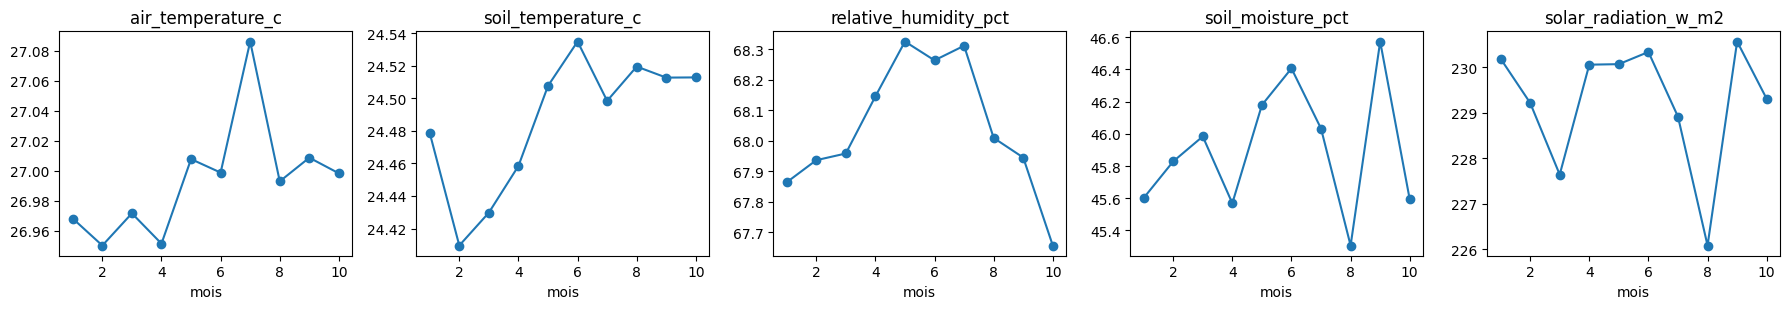

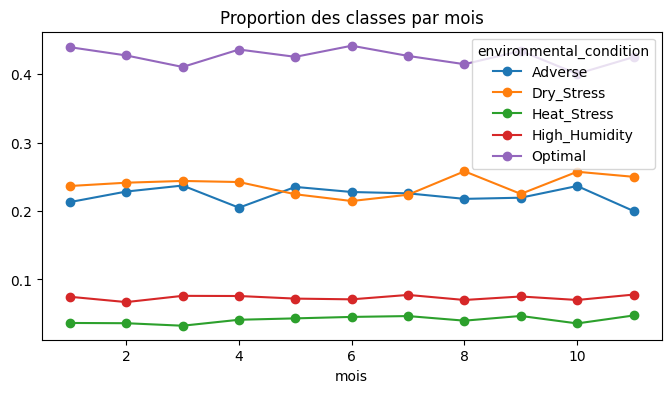

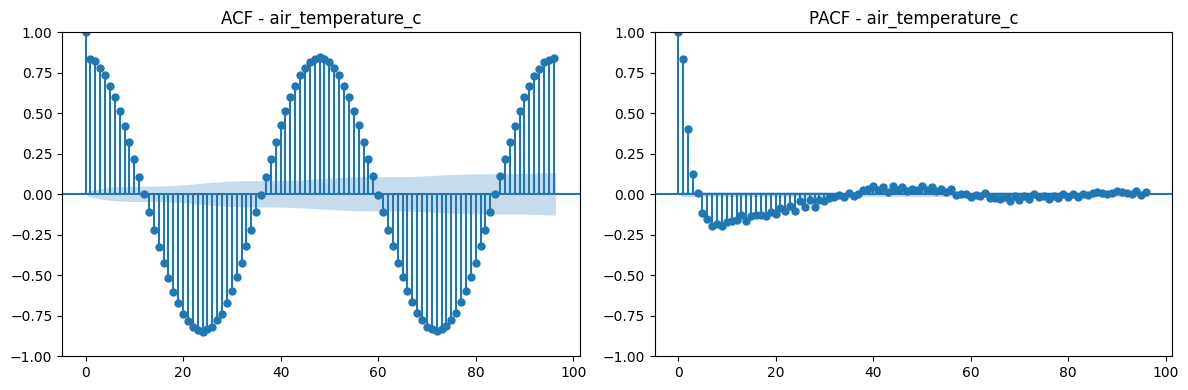

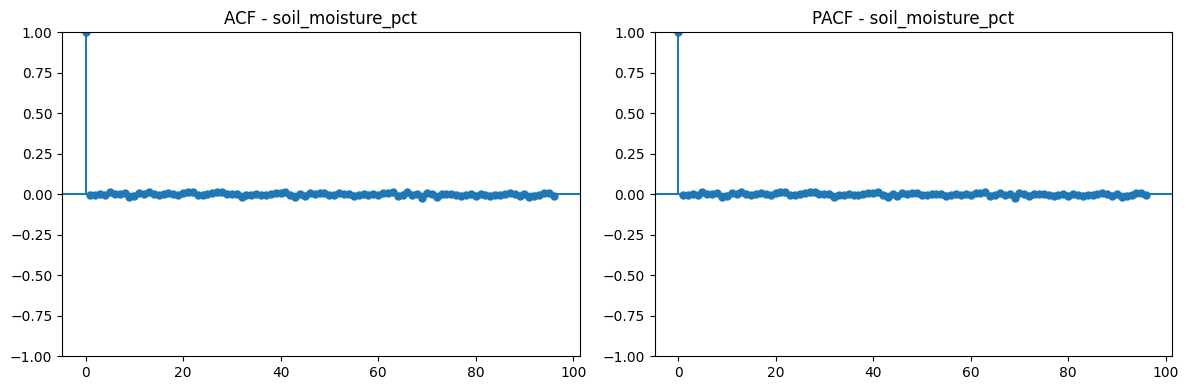

Nombre de lignes : 99
     section                                                  metrique      valeur
saisonnalite                   air_temperature_c_moyenne_mensuelle_min   26.950316
saisonnalite                   air_temperature_c_moyenne_mensuelle_max   27.086277
saisonnalite                   air_temperature_c_ecart_relatif_max_min    0.005037
saisonnalite                  soil_temperature_c_moyenne_mensuelle_min   24.409547
saisonnalite                  soil_temperature_c_moyenne_mensuelle_max   24.534944
saisonnalite                  soil_temperature_c_ecart_relatif_max_min    0.005121
saisonnalite               relative_humidity_pct_moyenne_mensuelle_min   67.656821
saisonnalite               relative_humidity_pct_moyenne_mensuelle_max   68.325753
saisonnalite               relative_humidity_pct_ecart_relatif_max_min    0.009831
saisonnalite                   soil_moisture_pct_moyenne_mensuelle_min   45.306284
saisonnalite                   soil_moisture_pct_moyenne_mensuell

In [83]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

DOSSIER_FIG = "/kaggle/working/results/figures"
os.makedirs(DOSSIER_FIG, exist_ok=True)
CIBLE = "environmental_condition"

df["mois"] = df["timestamp"].dt.month
df["heure"] = df["timestamp"].dt.hour

# Variables continues testées (on exclut les variables d'irrigation, liées à la cible)
VARIABLES = [
    "air_temperature_c", "relative_humidity_pct", "soil_temperature_c", "soil_moisture_pct",
    "soil_ph", "soil_ec_ds_m", "nitrogen_mg_kg", "phosphorus_mg_kg", "potassium_mg_kg",
    "atmospheric_pressure_hpa", "solar_radiation_w_m2", "light_intensity_lux",
    "wind_speed_m_s", "wind_direction_deg", "rainfall_mm", "leaf_wetness_pct",
    "co2_ppm", "evapotranspiration_mm", "battery_level_pct", "signal_strength_dbm",
]

# 1. ADF (stationnarité) et Ljung-Box lag 48 (dépendance) pour TOUTES les variables
for var in VARIABLES:
    s = df[var].dropna()
    p_adf = adfuller(s, autolag="AIC", result_object=False)[1]
    p_lb = acorr_ljungbox(s, lags=[48], return_df=True)["lb_pvalue"].iloc[0]
    add("tests", f"{var}_adf_pvalue", p_adf)
    add("tests", f"{var}_ljungbox_lag48_pvalue", p_lb)

# 2. Saisonnalité mensuelle (novembre exclu : seulement 8 jours de données)
VARS_SAISON = ["air_temperature_c", "soil_temperature_c", "relative_humidity_pct",
               "soil_moisture_pct", "solar_radiation_w_m2"]
mensuel = df[df["mois"] <= 10].groupby("mois")[VARS_SAISON].mean()
for var in VARS_SAISON:
    add("saisonnalite", f"{var}_moyenne_mensuelle_min", mensuel[var].min())
    add("saisonnalite", f"{var}_moyenne_mensuelle_max", mensuel[var].max())
    add("saisonnalite", f"{var}_ecart_relatif_max_min",
        (mensuel[var].max() - mensuel[var].min()) / mensuel[var].mean())

fig, axes = plt.subplots(1, len(VARS_SAISON), figsize=(18, 3.2))
for ax, var in zip(axes, VARS_SAISON):
    mensuel[var].plot(ax=ax, marker="o", title=var)
    ax.set_xlabel("mois")
plt.tight_layout()
plt.savefig(f"{DOSSIER_FIG}/saisonnalite_mensuelle.png", dpi=120)
plt.show()

# 3. Target drift : proportions mensuelles + test du chi2 (mois x classe)
derive = pd.crosstab(df["mois"], df[CIBLE], normalize="index")
derive10 = derive.loc[1:10]
for classe in derive.columns:
    add("target_drift", f"{classe}_proportion_mensuelle_min", derive10[classe].min())
    add("target_drift", f"{classe}_proportion_mensuelle_max", derive10[classe].max())
comptes = pd.crosstab(df.loc[df["mois"] <= 10, "mois"], df.loc[df["mois"] <= 10, CIBLE])
add("target_drift", "chi2_mois_classe_pvalue", chi2_contingency(comptes)[1])

derive.plot(figsize=(8, 4), marker="o", title="Proportion des classes par mois")
plt.savefig(f"{DOSSIER_FIG}/target_drift_mensuel.png", dpi=120)
plt.show()

# 4. Lead-lag : y.corr(x.shift(k)) ; k > 0 signifie que x précède y de k pas de 30 min
def meilleur_decalage(x, y, ks=range(-48, 49)):
    corr = {k: y.corr(x.shift(k)) for k in ks}
    k_best = max(corr, key=lambda k: abs(corr[k]))
    return k_best, corr[k_best]

paires = [
    ("solar_radiation_w_m2", "air_temperature_c"),
    ("air_temperature_c", "relative_humidity_pct"),
    ("air_temperature_c", "soil_temperature_c"),
    ("relative_humidity_pct", "leaf_wetness_pct"),
]
for x_nom, y_nom in paires:
    k, c = meilleur_decalage(df[x_nom], df[y_nom])
    add("lead_lag", f"{x_nom}_vers_{y_nom}_meilleur_lag", k)
    add("lead_lag", f"{x_nom}_vers_{y_nom}_corr_max", c)

# Lead-lag avec la cible (indicateur 0/1 de la classe)
for x_nom, classe in [("air_temperature_c", "Heat_Stress"), ("relative_humidity_pct", "High_Humidity")]:
    y = (df[CIBLE] == classe).astype(int)
    k, c = meilleur_decalage(df[x_nom], y)
    add("lead_lag", f"{x_nom}_vers_{classe}_meilleur_lag", k)
    add("lead_lag", f"{x_nom}_vers_{classe}_corr_max", c)

# 5. Sauvegarde des figures ACF / PACF pour le rapport
for var in ["air_temperature_c", "soil_moisture_pct"]:
    s = df[var].dropna()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    plot_acf(s, lags=96, ax=axes[0], title=f"ACF - {var}")
    plot_pacf(s, lags=96, ax=axes[1], title=f"PACF - {var}", method="ywm")
    plt.tight_layout()
    plt.savefig(f"{DOSSIER_FIG}/acf_pacf_{var}.png", dpi=120)
    plt.show()

# 6. Sauvegarde du CSV (les doublons éventuels sont supprimés)
df_res = pd.DataFrame(resultats).drop_duplicates()
df_res.to_csv("/kaggle/working/results/Exploratory_temporal.csv", index=False, encoding="utf-8")
print("Nombre de lignes :", len(df_res))
print(df_res[df_res["section"].isin(["saisonnalite", "target_drift", "lead_lag"])].to_string(index=False))

test                      adf_p  ljungbox_p  stationnaire  dependance_temporelle
variable                                                                        
air_temperature_c           0.0      0.0000          True                   True
atmospheric_pressure_hpa    0.0      0.5338          True                  False
battery_level_pct           0.0      0.3856          True                  False
co2_ppm                     0.0      0.0509          True                  False
evapotranspiration_mm       0.0      0.0000          True                   True
leaf_wetness_pct            0.0      0.0000          True                   True
light_intensity_lux         0.0      0.0000          True                   True
nitrogen_mg_kg              0.0      0.0250          True                   True
phosphorus_mg_kg            0.0      0.3430          True                  False
potassium_mg_kg             0.0      0.8803          True                  False
rainfall_mm                 

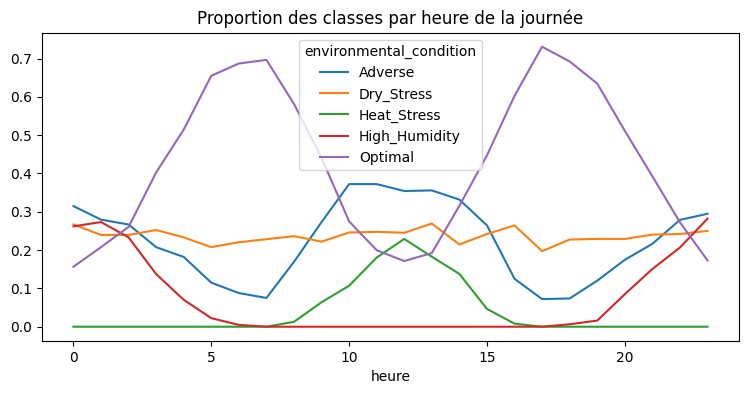

Nombre de lignes : 132
               section                                                  metrique    valeur
           lead_lag_6h  solar_radiation_w_m2_vers_air_temperature_c_meilleur_lag         0
           lead_lag_6h      solar_radiation_w_m2_vers_air_temperature_c_corr_max  0.819012
           lead_lag_6h     solar_radiation_w_m2_vers_air_temperature_c_corr_lag0  0.819012
           lead_lag_6h air_temperature_c_vers_relative_humidity_pct_meilleur_lag         0
           lead_lag_6h     air_temperature_c_vers_relative_humidity_pct_corr_max -0.766182
           lead_lag_6h    air_temperature_c_vers_relative_humidity_pct_corr_lag0 -0.766182
           lead_lag_6h    air_temperature_c_vers_soil_temperature_c_meilleur_lag         0
           lead_lag_6h        air_temperature_c_vers_soil_temperature_c_corr_max   0.96143
           lead_lag_6h       air_temperature_c_vers_soil_temperature_c_corr_lag0   0.96143
           lead_lag_6h  relative_humidity_pct_vers_leaf_wetness_pct

In [84]:
from scipy.stats import kruskal, chi2_contingency

# ---------------------------------------------------------------- 1. Résumé ADF / Ljung-Box
tests = pd.DataFrame(resultats).drop_duplicates()
tests = tests[tests["section"] == "tests"].copy()
tests["variable"] = tests["metrique"].str.replace(r"_(adf|ljungbox_lag48)_pvalue$", "", regex=True)
tests["test"] = np.where(tests["metrique"].str.contains("adf"), "adf_p", "ljungbox_p")
resume = tests.pivot(index="variable", columns="test", values="valeur").astype(float)
resume["stationnaire"] = resume["adf_p"] < 0.05
resume["dependance_temporelle"] = resume["ljungbox_p"] < 0.05
print(resume.round(4).to_string())
print("Variables avec dépendance temporelle :", list(resume.index[resume["dependance_temporelle"]]))

# ---------------------------------------------------------------- 2. Saisonnalité (Kruskal-Wallis)
for var in VARS_SAISON:
    groupes = [g[var].values for _, g in df[df["mois"] <= 10].groupby("mois")]
    add("saisonnalite", f"{var}_kruskal_mois_pvalue", kruskal(*groupes)[1])

# ---------------------------------------------------------------- 3. Lead-lag limité à +/- 6 h
def decalage_dans_la_journee(x, y, kmax=12):
    """Retourne (meilleur lag, corrélation à ce lag, corrélation à lag 0), lags en pas de 30 min."""
    corr = {k: y.corr(x.shift(k)) for k in range(-kmax, kmax + 1)}
    k_best = max(corr, key=lambda k: abs(corr[k]))
    return k_best, corr[k_best], corr[0]

for x_nom, y_nom in paires:
    k, c, c0 = decalage_dans_la_journee(df[x_nom], df[y_nom])
    add("lead_lag_6h", f"{x_nom}_vers_{y_nom}_meilleur_lag", k)
    add("lead_lag_6h", f"{x_nom}_vers_{y_nom}_corr_max", c)
    add("lead_lag_6h", f"{x_nom}_vers_{y_nom}_corr_lag0", c0)

# ---------------------------------------------------------------- 4. Cycle journalier de la cible
par_heure = pd.crosstab(df["heure"], df[CIBLE], normalize="index")
for classe in par_heure.columns:
    add("cycle_journalier_cible", f"{classe}_proportion_horaire_min", par_heure[classe].min())
    add("cycle_journalier_cible", f"{classe}_proportion_horaire_max", par_heure[classe].max())
    add("cycle_journalier_cible", f"{classe}_heure_du_max", int(par_heure[classe].idxmax()))
add("cycle_journalier_cible", "chi2_heure_classe_pvalue",
    chi2_contingency(pd.crosstab(df["heure"], df[CIBLE]))[1])

par_heure.plot(figsize=(9, 4), title="Proportion des classes par heure de la journée")
plt.xlabel("heure")
plt.savefig(f"{DOSSIER_FIG}/cible_par_heure.png", dpi=120)
plt.show()

# ---------------------------------------------------------------- 5. Sauvegarde
df_res = pd.DataFrame(resultats).drop_duplicates()
df_res.to_csv("/kaggle/working/results/Exploratory_temporal.csv", index=False, encoding="utf-8")
print("Nombre de lignes :", len(df_res))
nouvelles = ["lead_lag_6h", "cycle_journalier_cible"]
print(df_res[df_res["section"].isin(nouvelles)].to_string(index=False))
print(df_res[df_res["metrique"].str.contains("kruskal")].to_string(index=False))

In [85]:
from statsmodels.tsa.stattools import pacf

VARS_DEP = ["air_temperature_c", "soil_temperature_c", "relative_humidity_pct",
            "solar_radiation_w_m2", "light_intensity_lux", "evapotranspiration_mm",
            "leaf_wetness_pct", "nitrogen_mg_kg"]

# PACF aux lags 1 et 2 pour les variables à dépendance temporelle
for var in VARS_DEP:
    valeurs = pacf(df[var].dropna(), nlags=48, method="ywm")
    add("pacf", f"{var}_pacf_lag1", valeurs[1])
    add("pacf", f"{var}_pacf_lag2", valeurs[2])

# L'ancienne section lead_lag (+/- 24 h) contient des artefacts dus au cycle de 24 h :
# on la renomme pour éviter toute confusion avec lead_lag_6h
for ligne in resultats:
    if ligne["section"] == "lead_lag":
        ligne["section"] = "lead_lag_24h_artefact_cycle"

df_res = pd.DataFrame(resultats).drop_duplicates()
df_res.to_csv("/kaggle/working/results/Exploratory_temporal.csv", index=False, encoding="utf-8")
print("Nombre de lignes :", len(df_res))

Nombre de lignes : 148


In [86]:
import pandas as pd

# Mêmes paramètres que src/make_splits.py (dev = fin du développement avec 24 h de gap)
GAP_DEV_TEST = 48
n = len(df)
n_test = int(n * 0.2)
dev = df.iloc[: n - n_test - GAP_DEV_TEST]
test = df.iloc[n - n_test:]

# Mettre à jour les deux lignes 'split' calculées avant l'ajout du gap
for ligne in resultats:
    if ligne["section"] == "split" and ligne["metrique"] == "dev_date_fin":
        ligne["valeur"] = dev["timestamp"].max()
    if ligne["section"] == "split" and ligne["metrique"] == "test_date_debut":
        ligne["valeur"] = test["timestamp"].min()

df_res = pd.DataFrame(resultats).drop_duplicates()
df_res.to_csv("/kaggle/working/results/Exploratory_temporal.csv", index=False, encoding="utf-8")

print("Nombre de lignes :", len(df_res))  # attendu : 148
print(df_res[df_res["section"] == "split"].to_string(index=False))

Nombre de lignes : 148
section        metrique              valeur
  split    dev_date_fin 2024-09-05 23:30:00
  split test_date_debut 2024-09-07 00:00:00


In [90]:
import pandas as pd

# Fichier d'origine, sans le trier ni supprimer de lignes
df = pd.read_csv("/kaggle/input/datasets/colabsss/precision-agriculture-monitoring-dataset/precision_agriculture_dataset.csv")

val = pd.read_csv("results/splits/splits_validation.csv")
dev_idx = pd.read_csv("results/splits/dev_index.csv")["index"]
test_idx = pd.read_csv("results/splits/test_index.csv")["index"]  # à n'utiliser qu'à la fin
ts = pd.read_csv("results/splits/splits_temporel.csv")


def plis_stratifies(repetition, pli):
    """Retourne (train, validation) pour un pli de la validation croisée 3 x 10."""
    val_idx = val[(val["repetition"] == repetition) & (val["fold"] == pli)]["index"]
    train_idx = dev_idx[~dev_idx.isin(val_idx)]
    return df.loc[train_idx], df.loc[val_idx]


def plis_temporels(pli):
    """Retourne (train, validation) pour un pli du TimeSeriesSplit (5 plis, gap de 24 h)."""
    train_idx = ts[(ts["fold"] == pli) & (ts["ensemble"] == "train")]["index"]
    val_idx = ts[(ts["fold"] == pli) & (ts["ensemble"] == "val")]["index"]
    return df.loc[train_idx], df.loc[val_idx]